# London Fire Brigade – Animal Rescue Incident Analysis

## Project Overview

This project analyses animal rescue incidents recorded by the London Fire Brigade between 2009 and 2026.

The objective is to identify patterns in animal rescue incidents, understand when and where they occur, examine common rescue operations, and explore emergency response resource usage.

## Dataset

The dataset contains 14,046 records and 20 original columns covering animal rescue incidents, incident dates, locations, rescue types, and resource usage.

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [173]:
df = pd.read_csv("../Data/Animal_Rescue_LFB_2009-2026_20cols.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 1. Initial Data Inspection

The dataset is examined to understand its structure, dimensions, data types, statistical properties, missing values, and duplicate records.

In [174]:
df.head()

,IncidentNumber,DateTimeOfCall,CalYear,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£),AnimalGroupParent,OriginofCall,PropertyType,PropertyCategory,SpecialServiceTypeCategory,SpecialServiceType,Ward,Borough,StnGroundName,Street,PostcodeDistrict,Latitude,Longitude
0,139091,2009-01-01 03:01:00,2009,1.0,2.0,255,510.0,Dog,Person (land line),House - single occupancy,Dwelling,Other animal assistance,Animal assistance involving livestock - Other ...,Crystal Palace & Upper Norwood,Croydon,Norbury,Waddington Way,SE19,NaN,NaN
1,275091,2009-01-01 08:51:00,2009,1.0,1.0,255,255.0,Fox,Person (land line),Railings,Outdoor Structure,Other animal assistance,Animal assistance involving livestock - Other ...,Woodside,Croydon,Woodside,Grasmere Road,SE25,51.390954,-0.064167
2,2075091,2009-01-04 10:07:00,2009,1.0,1.0,255,255.0,Dog,Person (mobile),Pipe or drain,Outdoor Structure,Animal rescue from below ground,Animal rescue from below ground - Domestic pet,Carshalton Central,Sutton,Wallington,Mill Lane,SM5,51.368941,-0.161985
3,2872091,2009-01-05 12:27:00,2009,1.0,1.0,255,255.0,Horse,Person (mobile),"Intensive Farming Sheds (chickens, pigs etc)",Non Residential,Animal rescue from water,Animal rescue from water - Farm animal,Harefield Village,Hillingdon,Ruislip,Park Lane,UB9,51.605283,-0.489684
4,3553091,2009-01-06 15:23:00,2009,1.0,1.0,255,255.0,Rabbit,Person (mobile),House - single occupancy,Dwelling,Other animal assistance,Animal assistance involving livestock - Other ...,Gooshays,Havering,Harold Hill,Swindon Lane,RM3,NaN,NaN


In [175]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 14046
Number of columns: 20


In [176]:
df.columns

Index(['IncidentNumber', 'DateTimeOfCall', 'CalYear', 'PumpCount',
       'PumpHoursTotal', 'HourlyNotionalCost(£)', 'IncidentNotionalCost(£)',
       'AnimalGroupParent', 'OriginofCall', 'PropertyType', 'PropertyCategory',
       'SpecialServiceTypeCategory', 'SpecialServiceType', 'Ward', 'Borough',
       'StnGroundName', 'Street', 'PostcodeDistrict', 'Latitude', 'Longitude'],
      dtype='str')

In [177]:
df.tail()

,IncidentNumber,DateTimeOfCall,CalYear,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£),AnimalGroupParent,OriginofCall,PropertyType,PropertyCategory,SpecialServiceTypeCategory,SpecialServiceType,Ward,Borough,StnGroundName,Street,PostcodeDistrict,Latitude,Longitude
14041,154278-31072026,2026-07-31 08:48:00,2026,1.0,1.0,503,503.0,Cat,Person (mobile),House - single occupancy,Dwelling,Animal rescue from height,Animal rescue from height - Domestic pet,STONEBRIDGE,BRENT,Park Royal,MILTON AVENUE,NW10,NaN,NaN
14042,154420-31072026,2026-07-31 12:36:00,2026,1.0,1.0,503,503.0,Bird,Person (mobile),Purpose Built Flats/Maisonettes - Up to 3 stor...,Dwelling,Animal rescue from height,Animal rescue from height - Bird,HARRINGAY,HARINGEY,Tottenham,GRAND PARADE,N4,NaN,NaN
14043,154994-31072026,2026-07-31 21:43:00,2026,1.0,1.0,503,503.0,Bird,Person (mobile),Domestic garden (vegetation not equipment),Outdoor,Other animal assistance,Assist trapped wild animal,WOODHOUSE,BARNET,Finchley,MAYFIELD AVENUE,N12,51.618803,-0.169343
14044,155008-31072026,2026-07-31 21:54:00,2026,1.0,1.0,503,503.0,Cat,Person (mobile),Bungalow - single occupancy,Dwelling,Animal rescue from height,Animal rescue from height - Domestic pet,HERMITAGE & GARDENS,HARINGEY,Tottenham,KIMBERLEY GARDENS,N4,NaN,NaN
14045,155038-31072026,2026-07-31 22:32:00,2026,1.0,2.0,503,1006.0,Cat,Person (mobile),Domestic garden (vegetation not equipment),Outdoor,Animal rescue from height,Animal rescue from height - Domestic pet,BOLEYN,NEWHAM,East Ham,KATHERINE ROAD,E6,51.536556,0.045006


In [178]:
df.sample(5)

,IncidentNumber,DateTimeOfCall,CalYear,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£),AnimalGroupParent,OriginofCall,PropertyType,PropertyCategory,SpecialServiceTypeCategory,SpecialServiceType,Ward,Borough,StnGroundName,Street,PostcodeDistrict,Latitude,Longitude
11916,051444-27032025,2025-03-27 18:37:00,2025,1.0,1.0,430,430.0,Bird,Person (mobile),Purpose Built Flats/Maisonettes - 4 to 9 storeys,Dwelling,Animal rescue from height,Animal rescue from height - Bird,ROEHAMPTON,WANDSWORTH,Wandsworth,TUNWORTH CRESCENT,SW15,NaN,NaN
9385,051289-13042023,2023-04-13 17:22:00,2023,1.0,1.0,388,388.0,Fox,Person (mobile),House - single occupancy,Dwelling,Other animal assistance,Assist trapped wild animal,EASTBROOK & RUSH GREEN,BARKING AND DAGENHAM,Dagenham,BELL FARM AVENUE,RM10,NaN,NaN
2777,104299131,2013-08-01 07:35:00,2013,1.0,1.0,290,290.0,Cat,Person (land line),Purpose Built Flats/Maisonettes - 4 to 9 storeys,Dwelling,Animal rescue from height,Animal rescue from height - Domestic pet,Lea Bridge,Hackney,Homerton,Lea Bridge Road,E5,NaN,NaN
9932,124885-17082023,2023-08-17 20:58:00,2023,1.0,1.0,388,388.0,Cat,Person (mobile),Tree scrub,Outdoor,Animal rescue from height,Animal rescue from height - Domestic pet,VALENTINES,REDBRIDGE,Ilford,EMPRESS AVENUE,IG1,51.564327,0.063547
7549,065503-01062021,2021-06-01 16:05:00,2021,1.0,1.0,352,352.0,Bird,Person (mobile),Purpose built office,Non Residential,Animal rescue from height,Animal rescue from height - Bird,Camden Town,CAMDEN,Kentish Town,BAYHAM STREET,NW1,51.538131,-0.140753


In [179]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14046 entries, 0 to 14045
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   IncidentNumber              14046 non-null  str    
 1   DateTimeOfCall              14046 non-null  str    
 2   CalYear                     14046 non-null  int64  
 3   PumpCount                   13944 non-null  float64
 4   PumpHoursTotal              13940 non-null  float64
 5   HourlyNotionalCost(£)       14046 non-null  int64  
 6   IncidentNotionalCost(£)     13940 non-null  float64
 7   AnimalGroupParent           14046 non-null  str    
 8   OriginofCall                14046 non-null  str    
 9   PropertyType                14046 non-null  str    
 10  PropertyCategory            14046 non-null  str    
 11  SpecialServiceTypeCategory  14046 non-null  str    
 12  SpecialServiceType          14046 non-null  str    
 13  Ward                        14024 non-null

In [180]:
df.describe()

,CalYear,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£),Latitude,Longitude
count,14046.000000,13944.000000,13940.000000,14046.000000,13940.000000,6404.000000,6404.000000
mean,2018.991029,1.014917,1.164778,355.380037,412.376686,51.463874,-0.114732
std,5.285854,0.128686,0.569857,71.901573,208.040567,1.578028,0.159798
min,2009.000000,1.000000,0.000000,255.000000,0.000000,0.000000,-0.559730
25%,2014.000000,1.000000,1.000000,295.000000,298.000000,51.459882,-0.216875
50%,2020.000000,1.000000,1.000000,346.000000,352.000000,51.515997,-0.105706
75%,2024.000000,1.000000,1.000000,388.000000,430.000000,51.568886,-0.016119
max,2026.000000,4.000000,12.000000,503.000000,3912.000000,51.688304,0.466421


In [181]:
df.describe(include='object')

C:\Users\hp\AppData\Local\Temp\ipykernel_15176\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,IncidentNumber,DateTimeOfCall,AnimalGroupParent,OriginofCall,PropertyType,PropertyCategory,SpecialServiceTypeCategory,SpecialServiceType,Ward,Borough,StnGroundName,Street,PostcodeDistrict
count,14046,14046,14046,14046,14046,14046,14046,14046,14024,14031,14046,14046,14046
unique,14046,14026,29,8,200,7,4,24,1389,70,109,9397,285
top,139091,2009-07-11 11:26:00,Cat,Person (mobile),House - single occupancy,Dwelling,Other animal assistance,Animal rescue from height - Domestic pet,Gooshays,ENFIELD,Enfield,HIGH STREET,CR0
freq,1,2,7380,9782,3627,7642,6537,3712,42,463,259,81,273


In [182]:
df.isnull().sum()

IncidentNumber                   0
DateTimeOfCall                   0
CalYear                          0
PumpCount                      102
PumpHoursTotal                 106
HourlyNotionalCost(£)            0
IncidentNotionalCost(£)        106
AnimalGroupParent                0
OriginofCall                     0
PropertyType                     0
PropertyCategory                 0
SpecialServiceTypeCategory       0
SpecialServiceType               0
Ward                            22
Borough                         15
StnGroundName                    0
Street                           0
PostcodeDistrict                 0
Latitude                      7642
Longitude                     7642
dtype: int64

In [183]:
(df.isnull().sum() / len(df) * 100).round(2)

IncidentNumber                 0.00
DateTimeOfCall                 0.00
CalYear                        0.00
PumpCount                      0.73
PumpHoursTotal                 0.75
HourlyNotionalCost(£)          0.00
IncidentNotionalCost(£)        0.75
AnimalGroupParent              0.00
OriginofCall                   0.00
PropertyType                   0.00
PropertyCategory               0.00
SpecialServiceTypeCategory     0.00
SpecialServiceType             0.00
Ward                           0.16
Borough                        0.11
StnGroundName                  0.00
Street                         0.00
PostcodeDistrict               0.00
Latitude                      54.41
Longitude                     54.41
dtype: float64

In [184]:
df.duplicated().sum()

np.int64(0)

In [185]:
df.memory_usage(deep=True).sum() / (1024 ** 2)

np.float64(11.955148696899414)

## 2. Data Cleaning and Preparation

The dataset is checked and cleaned for missing values, duplicate records, incorrect data types, inconsistent text values, and invalid geographical coordinates.

A separate copy is used to preserve the original dataset.

In [186]:
df_clean = df.copy()

In [187]:
print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (14046, 20)
Working dataset: (14046, 20)


In [188]:
df_clean['DateTimeOfCall'].head(10)

0    2009-01-01 03:01:00
1    2009-01-01 08:51:00
2    2009-01-04 10:07:00
3    2009-01-05 12:27:00
4    2009-01-06 15:23:00
5    2009-01-06 19:30:00
6    2009-01-07 06:29:00
7    2009-01-07 11:55:00
8    2009-01-07 13:48:00
9    2009-01-07 21:24:00
Name: DateTimeOfCall, dtype: str

In [189]:
df_clean['DateTimeOfCall'] = pd.to_datetime(
    df_clean['DateTimeOfCall'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
)

In [190]:
print(df_clean['DateTimeOfCall'].dtype)

datetime64[us]


In [191]:
df_clean['DateTimeOfCall'].head()

0   2009-01-01 03:01:00
1   2009-01-01 08:51:00
2   2009-01-04 10:07:00
3   2009-01-05 12:27:00
4   2009-01-06 15:23:00
Name: DateTimeOfCall, dtype: datetime64[us]

In [192]:
df_clean['DateTimeOfCall'].head(10)

0   2009-01-01 03:01:00
1   2009-01-01 08:51:00
2   2009-01-04 10:07:00
3   2009-01-05 12:27:00
4   2009-01-06 15:23:00
5   2009-01-06 19:30:00
6   2009-01-07 06:29:00
7   2009-01-07 11:55:00
8   2009-01-07 13:48:00
9   2009-01-07 21:24:00
Name: DateTimeOfCall, dtype: datetime64[us]

In [193]:
df_clean['DateTimeOfCall'].isnull().sum()

np.int64(0)

In [194]:
df_clean[['DateTimeOfCall', 'CalYear']].head(10)

,DateTimeOfCall,CalYear
0,2009-01-01 03:01:00,2009
1,2009-01-01 08:51:00,2009
2,2009-01-04 10:07:00,2009
3,2009-01-05 12:27:00,2009
4,2009-01-06 15:23:00,2009
5,2009-01-06 19:30:00,2009
6,2009-01-07 06:29:00,2009
7,2009-01-07 11:55:00,2009
8,2009-01-07 13:48:00,2009
9,2009-01-07 21:24:00,2009


In [195]:
(df_clean['DateTimeOfCall'].dt.year != df_clean['CalYear']).sum()

np.int64(0)

In [196]:
df_clean[
    df_clean[['PumpCount', 'PumpHoursTotal', 'IncidentNotionalCost(£)']]
    .isnull()
    .any(axis=1)
][['IncidentNumber', 'PumpCount', 'PumpHoursTotal', 'IncidentNotionalCost(£)']]

,IncidentNumber,PumpCount,PumpHoursTotal,IncidentNotionalCost(£)
314,119148091,NaN,NaN,NaN
355,132513091,NaN,NaN,NaN
523,208663091,NaN,NaN,NaN
1268,43265111,NaN,NaN,NaN
1394,76409111,NaN,NaN,NaN
...,...,...,...,...
13709,108260-09062026,1.0,NaN,NaN
13794,121459-26062026,NaN,NaN,NaN
13835,126196-01072026,NaN,NaN,NaN
13873,129454-05072026,NaN,NaN,NaN


In [197]:
df_clean[
    ['PumpCount', 'PumpHoursTotal', 'IncidentNotionalCost(£)']
].isnull().value_counts()

PumpCount  PumpHoursTotal  IncidentNotionalCost(£)
False      False           False                      13940
True       True            True                         102
False      True            True                           4
Name: count, dtype: int64

In [198]:
missing_resources = df_clean[
    df_clean[['PumpCount', 'PumpHoursTotal', 'IncidentNotionalCost(£)']]
    .isnull()
    .any(axis=1)
]

missing_resources[
    ['IncidentNumber', 'DateTimeOfCall', 'AnimalGroupParent',
     'SpecialServiceType', 'Borough', 'PumpCount',
     'PumpHoursTotal', 'IncidentNotionalCost(£)']
].head(15)

,IncidentNumber,DateTimeOfCall,AnimalGroupParent,SpecialServiceType,Borough,PumpCount,PumpHoursTotal,IncidentNotionalCost(£)
314,119148091,2009-07-05 09:25:00,Cat,Animal rescue from below ground - Domestic pet,Croydon,NaN,NaN,NaN
355,132513091,2009-07-25 11:17:00,Cat,Animal rescue from height - Domestic pet,Lewisham,NaN,NaN,NaN
523,208663091,2009-11-17 16:16:00,Horse,Animal assistance involving livestock - Other ...,Hillingdon,NaN,NaN,NaN
1268,43265111,2011-03-26 09:53:00,Dog,Animal rescue from water - Domestic pet,Lambeth,NaN,NaN,NaN
1394,76409111,2011-05-17 22:12:00,Unknown - Heavy Livestock Animal,Animal assistance involving livestock - Other ...,Hounslow,NaN,NaN,NaN
1415,84904111,2011-05-31 08:46:00,Bird,Animal rescue from below ground - Bird,Tower Hamlets,NaN,NaN,NaN
1557,122826111,2011-08-02 22:10:00,Fox,Animal rescue from below ground - Farm animal,Waltham Forest,NaN,NaN,NaN
1761,194986111,2011-12-04 12:39:00,Horse,Animal assistance involving livestock - Other ...,Enfield,NaN,NaN,NaN
1900,35453121,2012-03-15 10:32:00,Cat,Animal rescue from height - Domestic pet,Kensington and Chelsea,NaN,NaN,NaN
1909,36995121,2012-03-18 11:39:00,Horse,Animal assistance - Lift heavy livestock animal,Croydon,NaN,NaN,NaN


In [199]:
missing_resources['CalYear'].value_counts().sort_index()

CalYear
2009     3
2011     5
2012     7
2013     1
2014     6
2015     3
2016     2
2017     2
2018     9
2019     6
2020     4
2021    10
2022     7
2023     7
2024     8
2025    13
2026    13
Name: count, dtype: int64

In [200]:
numeric_columns = [
    'PumpCount',
    'PumpHoursTotal',
    'HourlyNotionalCost(£)',
    'IncidentNotionalCost(£)'
]

df_clean[numeric_columns].describe()

,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£)
count,13944.000000,13940.000000,14046.000000,13940.000000
mean,1.014917,1.164778,355.380037,412.376686
std,0.128686,0.569857,71.901573,208.040567
min,1.000000,0.000000,255.000000,0.000000
25%,1.000000,1.000000,295.000000,298.000000
50%,1.000000,1.000000,346.000000,352.000000
75%,1.000000,1.000000,388.000000,430.000000
max,4.000000,12.000000,503.000000,3912.000000


In [201]:
(df_clean[numeric_columns] < 0).sum()

PumpCount                  0
PumpHoursTotal             0
HourlyNotionalCost(£)      0
IncidentNotionalCost(£)    0
dtype: int64

In [202]:
(df_clean[numeric_columns] == 0).sum()

PumpCount                  0
PumpHoursTotal             2
HourlyNotionalCost(£)      0
IncidentNotionalCost(£)    2
dtype: int64

In [203]:
zero_records = df_clean[
    (df_clean['PumpHoursTotal'] == 0) |
    (df_clean['IncidentNotionalCost(£)'] == 0)
]

zero_records[
    ['IncidentNumber', 'DateTimeOfCall', 'AnimalGroupParent',
     'SpecialServiceType', 'PumpCount', 'PumpHoursTotal',
     'HourlyNotionalCost(£)', 'IncidentNotionalCost(£)']
]

,IncidentNumber,DateTimeOfCall,AnimalGroupParent,SpecialServiceType,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£)
5844,174921-14122018,2018-12-14 20:15:00,Dog,Animal assistance involving domestic animal - ...,1.0,0.0,333,0.0
8618,096571-01072022,2022-07-01 10:39:00,Cat,Animal rescue from height - Domestic pet,1.0,0.0,364,0.0


In [204]:
df_clean.nlargest(10, 'PumpHoursTotal')[
    ['IncidentNumber', 'DateTimeOfCall', 'AnimalGroupParent',
     'SpecialServiceType', 'PumpCount', 'PumpHoursTotal',
     'IncidentNotionalCost(£)']
]

,IncidentNumber,DateTimeOfCall,AnimalGroupParent,SpecialServiceType,PumpCount,PumpHoursTotal,IncidentNotionalCost(£)
2542,48360131,2013-04-19 07:01:00,Horse,Animal assistance - Lift heavy livestock animal,2.0,12.0,3480.0
4450,098141-28072016,2016-07-28 13:49:00,Cat,Animal assistance involving domestic animal - ...,3.0,12.0,3912.0
3757,62700151,2015-05-22 11:34:00,Horse,Animal rescue from water - Farm animal,2.0,10.0,2980.0
1289,49189111,2011-04-06 02:03:00,Horse,Animal rescue from water - Farm animal,3.0,9.0,2340.0
1407,82423111,2011-05-27 06:50:00,Horse,Animal rescue from water - Farm animal,3.0,9.0,2340.0
1477,101755111,2011-06-29 21:04:00,Deer,Wild animal rescue from water or mud,3.0,9.0,2340.0
3143,49076141,2014-04-22 09:54:00,Cat,Assist trapped domestic animal,2.0,9.0,2655.0
8258,036972-15032022,2022-03-15 14:07:00,Dog,Animal rescue from below ground - Domestic pet,1.0,9.0,3168.0
8980,169921-15102022,2022-10-15 11:21:00,Dog,Animal rescue from water - Domestic pet,2.0,9.0,3276.0
874,100611101,2010-06-26 15:29:00,Cat,Animal rescue from height - Domestic pet,3.0,8.0,2080.0


In [205]:
df_clean[['Latitude', 'Longitude']].describe()

,Latitude,Longitude
count,6404.000000,6404.000000
mean,51.463874,-0.114732
std,1.578028,0.159798
min,0.000000,-0.559730
25%,51.459882,-0.216875
50%,51.515997,-0.105706
75%,51.568886,-0.016119
max,51.688304,0.466421


In [206]:
(df_clean[['Latitude', 'Longitude']] == 0).sum()

Latitude     6
Longitude    6
dtype: int64

In [207]:
invalid_coordinates = df_clean[
    (
        df_clean['Latitude'].notna() &
        ~df_clean['Latitude'].between(51.2, 51.8)
    ) |
    (
        df_clean['Longitude'].notna() &
        ~df_clean['Longitude'].between(-0.6, 0.4)
    )
]

print("Potentially invalid coordinate records:", len(invalid_coordinates))

Potentially invalid coordinate records: 8


In [208]:
invalid_coordinates[
    ['IncidentNumber', 'DateTimeOfCall', 'Borough',
     'PostcodeDistrict', 'Latitude', 'Longitude']
]

,IncidentNumber,DateTimeOfCall,Borough,PostcodeDistrict,Latitude,Longitude
5896,012249-30012019,2019-01-30 11:26:00,NaN,ME3,51.471845,0.466421
7028,116751-10092020,2020-09-10 20:49:00,NEWHAM,E20,0.000000,0.000000
7608,071683-12062021,2021-06-12 21:56:00,KINGSTON UPON THAMES,KT6,0.000000,0.000000
9513,068088-15052023,2023-05-15 18:28:00,BARKING AND DAGENHAM,IG11,0.000000,0.000000
9941,126778-21082023,2023-08-21 07:36:00,NaN,TN8,51.117707,0.095997
11813,034530-28022025,2025-02-28 11:51:00,BRENT,HA0,0.000000,0.000000
12967,221959-26112025,2025-11-26 10:28:00,EALING,W3,0.000000,0.000000
13837,126295-01072026,2026-07-01 18:27:00,LAMBETH,SE1,0.000000,0.000000


In [209]:
df_clean[
    (df_clean['Latitude'] == 0) |
    (df_clean['Longitude'] == 0)
][['IncidentNumber', 'Borough', 'Latitude', 'Longitude']]

,IncidentNumber,Borough,Latitude,Longitude
7028,116751-10092020,NEWHAM,0.0,0.0
7608,071683-12062021,KINGSTON UPON THAMES,0.0,0.0
9513,068088-15052023,BARKING AND DAGENHAM,0.0,0.0
11813,034530-28022025,BRENT,0.0,0.0
12967,221959-26112025,EALING,0.0,0.0
13837,126295-01072026,LAMBETH,0.0,0.0


In [210]:
zero_coordinates = (
    (df_clean['Latitude'] == 0) |
    (df_clean['Longitude'] == 0)
)

df_clean.loc[zero_coordinates, ['Latitude', 'Longitude']] = np.nan

In [211]:
print("Remaining zero latitudes:",
      (df_clean['Latitude'] == 0).sum())

print("Remaining zero longitudes:",
      (df_clean['Longitude'] == 0).sum())

print("Missing latitude values:",
      df_clean['Latitude'].isnull().sum())

print("Missing longitude values:",
      df_clean['Longitude'].isnull().sum())

print("Dataset shape:", df_clean.shape)

Remaining zero latitudes: 0
Remaining zero longitudes: 0
Missing latitude values: 7648
Missing longitude values: 7648
Dataset shape: (14046, 20)


In [212]:
df_clean['IncidentNumber'].duplicated().sum()

np.int64(0)

In [213]:
categorical_columns = [
    'AnimalGroupParent',
    'OriginofCall',
    'PropertyCategory',
    'SpecialServiceTypeCategory',
    'Borough'
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts(dropna=False))


AnimalGroupParent:
AnimalGroupParent
Cat                                                        7380
Bird                                                       2743
Dog                                                        1825
Fox                                                         855
Unknown - Domestic Animal Or Pet                            266
Horse                                                       238
Deer                                                        238
Unknown - Wild Animal                                       147
Squirrel                                                    113
cat                                                          55
Unknown - Heavy Livestock Animal                             52
Rabbit                                                       22
Snake                                                        22
Hamster                                                      20
Ferret                                                       12
Co

In [214]:
for column in categorical_columns:
    print(f"\n--- {column} ---")

    values = df_clean[column].dropna().unique()

    for value in sorted(values):
        if value != value.strip() or value != value.title():
            print(repr(value))


--- AnimalGroupParent ---
'Unknown - Animal rescue from below ground - Farm animal'
'Unknown - Animal rescue from water - Farm animal'
'cat'

--- OriginofCall ---
'Not known'
'Other FRS'
'Person (land line)'
'Person (mobile)'
'Person (running call)'

--- PropertyCategory ---

--- SpecialServiceTypeCategory ---
'Animal rescue from below ground'
'Animal rescue from height'
'Animal rescue from water'
'Other animal assistance'

--- Borough ---
'BARKING AND DAGENHAM'
'BARNET'
'BEXLEY'
'BRENT'
'BROMLEY'
'Barking and Dagenham'
'CAMDEN'
'CITY OF LONDON'
'CROYDON'
'City of London'
'EALING'
'ENFIELD'
'GREENWICH'
'HACKNEY'
'HAMMERSMITH AND FULHAM'
'HARINGEY'
'HARROW'
'HAVERING'
'HILLINGDON'
'HOUNSLOW'
'Hammersmith and Fulham'
'ISLINGTON'
'KENSINGTON AND CHELSEA'
'KINGSTON UPON THAMES'
'Kensington and Chelsea'
'Kingston upon Thames'
'LAMBETH'
'LEWISHAM'
'MERTON'
'NEWHAM'
'REDBRIDGE'
'RICHMOND UPON THAMES'
'Richmond upon Thames'
'SOUTHWARK'
'SUTTON'
'TOWER HAMLETS'
'WALTHAM FOREST'
'WANDSWORTH'
'W

In [215]:
categorical_columns = df_clean.select_dtypes(
    include=['object', 'str']
).columns

In [216]:
df_clean['AnimalGroupParent'] = (
    df_clean['AnimalGroupParent'].str.strip().str.title()
)

In [217]:
df_clean['AnimalGroupParent'].value_counts()

AnimalGroupParent
Cat                                                        7435
Bird                                                       2743
Dog                                                        1825
Fox                                                         855
Unknown - Domestic Animal Or Pet                            266
Horse                                                       238
Deer                                                        238
Unknown - Wild Animal                                       147
Squirrel                                                    113
Unknown - Heavy Livestock Animal                             52
Rabbit                                                       22
Snake                                                        22
Hamster                                                      20
Ferret                                                       12
Cow                                                           9
Sheep                 

In [218]:
categorical_columns = df_clean.select_dtypes(
    include=['object', 'str']
).columns

for column in categorical_columns:
    space_count = df_clean[column].astype('string').str.strip().ne(
        df_clean[column].astype('string')
    ).sum()

    if space_count > 0:
        print(f"{column}: {space_count} values have extra spaces")

PropertyType: 11914 values have extra spaces


In [219]:
property_examples = df_clean['PropertyType'].dropna().unique()

for value in property_examples[:20]:
    print(repr(value))

'House - single occupancy '
'Railings'
'Pipe or drain '
'Intensive Farming Sheds (chickens, pigs etc) '
'Park '
'Lake/pond/reservoir '
'River/canal '
'Tree scrub '
'Car '
'Other animal boarding/breeding establishment'
'Wasteland '
'Woodland/forest - broadleaf/hardwood '
'Road surface/pavement '
'Purpose Built Flats/Maisonettes - Up to 3 storeys '
'Private garage '
'Cycle path/public footpath/bridleway '
'Domestic garden (vegetation not equipment) '
'Public toilets '
'Beach '
'Tenement Building '


In [220]:
df_clean['PropertyType'] = df_clean['PropertyType'].str.strip()

In [221]:
df_clean['PropertyType'].str.strip().ne(
    df_clean['PropertyType']
).sum()

np.int64(0)

In [222]:
for column in categorical_columns:
    if column == 'PropertyType':
        continue

    space_count = (
        df_clean[column]
        .astype('string')
        .str.strip()
        .ne(df_clean[column].astype('string'))
        .sum()
    )

    if space_count > 0:
        print(f"{column}: {space_count} values have extra spaces")

In [223]:
print("Earliest incident:", df_clean['DateTimeOfCall'].min())
print("Latest incident:", df_clean['DateTimeOfCall'].max())

print("\nRecords per year:")
print(df_clean['CalYear'].value_counts().sort_index())

Earliest incident: 2009-01-01 03:01:00
Latest incident: 2026-07-31 22:32:00

Records per year:
CalYear
2009     568
2010     611
2011     620
2012     603
2013     585
2014     583
2015     540
2016     604
2017     539
2018     610
2019     604
2020     758
2021     885
2022    1029
2023    1193
2024    1326
2025    1414
2026     974
Name: count, dtype: int64


In [224]:
print("Years outside expected range:")
print(
    df_clean[
        ~df_clean['CalYear'].between(2009, 2026)
    ]['CalYear'].unique()
)

print("\nMissing year values:")
print(df_clean['CalYear'].isnull().sum())

Years outside expected range:
[]

Missing year values:
0


In [225]:
df_clean.dtypes

IncidentNumber                           str
DateTimeOfCall                datetime64[us]
CalYear                                int64
PumpCount                            float64
PumpHoursTotal                       float64
HourlyNotionalCost(£)                  int64
IncidentNotionalCost(£)              float64
AnimalGroupParent                        str
OriginofCall                             str
PropertyType                             str
PropertyCategory                         str
SpecialServiceTypeCategory               str
SpecialServiceType                       str
Ward                                     str
Borough                                  str
StnGroundName                            str
Street                                   str
PostcodeDistrict                         str
Latitude                             float64
Longitude                            float64
dtype: object

In [226]:
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nTotal missing values:")
print(df_clean.isnull().sum())

print("\nTotal missing cells:", df_clean.isnull().sum().sum())

Original dataset shape: (14046, 20)
Cleaned dataset shape: (14046, 20)

Total missing values:
IncidentNumber                   0
DateTimeOfCall                   0
CalYear                          0
PumpCount                      102
PumpHoursTotal                 106
HourlyNotionalCost(£)            0
IncidentNotionalCost(£)        106
AnimalGroupParent                0
OriginofCall                     0
PropertyType                     0
PropertyCategory                 0
SpecialServiceTypeCategory       0
SpecialServiceType               0
Ward                            22
Borough                         15
StnGroundName                    0
Street                           0
PostcodeDistrict                 0
Latitude                      7648
Longitude                     7648
dtype: int64

Total missing cells: 15647


## 3. Feature Engineering

New time-based features are extracted from the incident date and time to support temporal analysis.

These include Year, Month, Month Name, Hour, Day of Week, and Time of Day.

In [227]:
df_clean['Year'] = df_clean['DateTimeOfCall'].dt.year

In [228]:
df_clean[['DateTimeOfCall', 'CalYear', 'Year']].head(10)

,DateTimeOfCall,CalYear,Year
0,2009-01-01 03:01:00,2009,2009
1,2009-01-01 08:51:00,2009,2009
2,2009-01-04 10:07:00,2009,2009
3,2009-01-05 12:27:00,2009,2009
4,2009-01-06 15:23:00,2009,2009
5,2009-01-06 19:30:00,2009,2009
6,2009-01-07 06:29:00,2009,2009
7,2009-01-07 11:55:00,2009,2009
8,2009-01-07 13:48:00,2009,2009
9,2009-01-07 21:24:00,2009,2009


In [229]:
df_clean['Month'] = df_clean['DateTimeOfCall'].dt.month

In [230]:
df_clean[['DateTimeOfCall', 'Month']].head(10)

,DateTimeOfCall,Month
0,2009-01-01 03:01:00,1
1,2009-01-01 08:51:00,1
2,2009-01-04 10:07:00,1
3,2009-01-05 12:27:00,1
4,2009-01-06 15:23:00,1
5,2009-01-06 19:30:00,1
6,2009-01-07 06:29:00,1
7,2009-01-07 11:55:00,1
8,2009-01-07 13:48:00,1
9,2009-01-07 21:24:00,1


In [231]:
df_clean['MonthName'] = df_clean['DateTimeOfCall'].dt.month_name()

In [232]:
df_clean[['DateTimeOfCall', 'Month', 'MonthName']].head(10)

,DateTimeOfCall,Month,MonthName
0,2009-01-01 03:01:00,1,January
1,2009-01-01 08:51:00,1,January
2,2009-01-04 10:07:00,1,January
3,2009-01-05 12:27:00,1,January
4,2009-01-06 15:23:00,1,January
5,2009-01-06 19:30:00,1,January
6,2009-01-07 06:29:00,1,January
7,2009-01-07 11:55:00,1,January
8,2009-01-07 13:48:00,1,January
9,2009-01-07 21:24:00,1,January


In [233]:
df_clean['Hour'] = df_clean['DateTimeOfCall'].dt.hour

In [234]:
df_clean[['DateTimeOfCall', 'Hour']].head(15)

,DateTimeOfCall,Hour
0,2009-01-01 03:01:00,3
1,2009-01-01 08:51:00,8
2,2009-01-04 10:07:00,10
3,2009-01-05 12:27:00,12
4,2009-01-06 15:23:00,15
5,2009-01-06 19:30:00,19
6,2009-01-07 06:29:00,6
7,2009-01-07 11:55:00,11
8,2009-01-07 13:48:00,13
9,2009-01-07 21:24:00,21


In [235]:
df_clean['DayOfWeek'] = df_clean['DateTimeOfCall'].dt.day_name()

In [236]:
df_clean[['DateTimeOfCall', 'DayOfWeek']].head(15)

,DateTimeOfCall,DayOfWeek
0,2009-01-01 03:01:00,Thursday
1,2009-01-01 08:51:00,Thursday
2,2009-01-04 10:07:00,Sunday
3,2009-01-05 12:27:00,Monday
4,2009-01-06 15:23:00,Tuesday
5,2009-01-06 19:30:00,Tuesday
6,2009-01-07 06:29:00,Wednesday
7,2009-01-07 11:55:00,Wednesday
8,2009-01-07 13:48:00,Wednesday
9,2009-01-07 21:24:00,Wednesday


In [237]:
def categorize_time(hour):
    if 0 <= hour < 6:
        return 'Night'
    elif 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'


df_clean['TimeOfDay'] = df_clean['Hour'].apply(categorize_time)

In [238]:
df_clean[['DateTimeOfCall', 'Hour', 'TimeOfDay']].head(20)

,DateTimeOfCall,Hour,TimeOfDay
0,2009-01-01 03:01:00,3,Night
1,2009-01-01 08:51:00,8,Morning
2,2009-01-04 10:07:00,10,Morning
3,2009-01-05 12:27:00,12,Afternoon
4,2009-01-06 15:23:00,15,Afternoon
5,2009-01-06 19:30:00,19,Evening
6,2009-01-07 06:29:00,6,Morning
7,2009-01-07 11:55:00,11,Morning
8,2009-01-07 13:48:00,13,Afternoon
9,2009-01-07 21:24:00,21,Evening


In [239]:
new_columns = [
    'Year',
    'Month',
    'MonthName',
    'Hour',
    'DayOfWeek',
    'TimeOfDay'
]

print("Missing values in new columns:")
print(df_clean[new_columns].isnull().sum())

print("\nTimeOfDay categories:")
print(df_clean['TimeOfDay'].value_counts())

print("\nMonth range:")
print(df_clean['Month'].min(), "-", df_clean['Month'].max())

print("\nHour range:")
print(df_clean['Hour'].min(), "-", df_clean['Hour'].max())

Missing values in new columns:
Year         0
Month        0
MonthName    0
Hour         0
DayOfWeek    0
TimeOfDay    0
dtype: int64

TimeOfDay categories:
TimeOfDay
Afternoon    5276
Evening      4300
Morning      3605
Night         865
Name: count, dtype: int64

Month range:
1 - 12

Hour range:
0 - 23


# 4. Exploratory Data Analysis (EDA)

This section explores animal rescue incidents through statistical analysis and visualisations to identify important patterns, trends, and relationships.

## EDA 1. Which animal groups account for the most rescue incidents?

This analysis compares the number of recorded incidents across animal groups. The percentages show each group's share of all 14,046 recorded incidents.


In [240]:
animal_counts = df_clean['AnimalGroupParent'].value_counts()

print(animal_counts)

AnimalGroupParent
Cat                                                        7435
Bird                                                       2743
Dog                                                        1825
Fox                                                         855
Unknown - Domestic Animal Or Pet                            266
Horse                                                       238
Deer                                                        238
Unknown - Wild Animal                                       147
Squirrel                                                    113
Unknown - Heavy Livestock Animal                             52
Rabbit                                                       22
Snake                                                        22
Hamster                                                      20
Ferret                                                       12
Cow                                                           9
Sheep                 

In [241]:
print("Total animal categories:", len(animal_counts))
print("\nTop 10 animal groups:")
print(animal_counts.head(10))

Total animal categories: 28

Top 10 animal groups:
AnimalGroupParent
Cat                                 7435
Bird                                2743
Dog                                 1825
Fox                                  855
Unknown - Domestic Animal Or Pet     266
Horse                                238
Deer                                 238
Unknown - Wild Animal                147
Squirrel                             113
Unknown - Heavy Livestock Animal      52
Name: count, dtype: int64


In [242]:
animal_summary = pd.DataFrame({
    'Incidents': animal_counts,
    'Percentage': (
        animal_counts / len(df_clean) * 100
    ).round(2)
})

print(animal_summary.head(10))

                                  Incidents  Percentage
AnimalGroupParent                                      
Cat                                    7435       52.93
Bird                                   2743       19.53
Dog                                    1825       12.99
Fox                                     855        6.09
Unknown - Domestic Animal Or Pet        266        1.89
Horse                                   238        1.69
Deer                                    238        1.69
Unknown - Wild Animal                   147        1.05
Squirrel                                113        0.80
Unknown - Heavy Livestock Animal         52        0.37


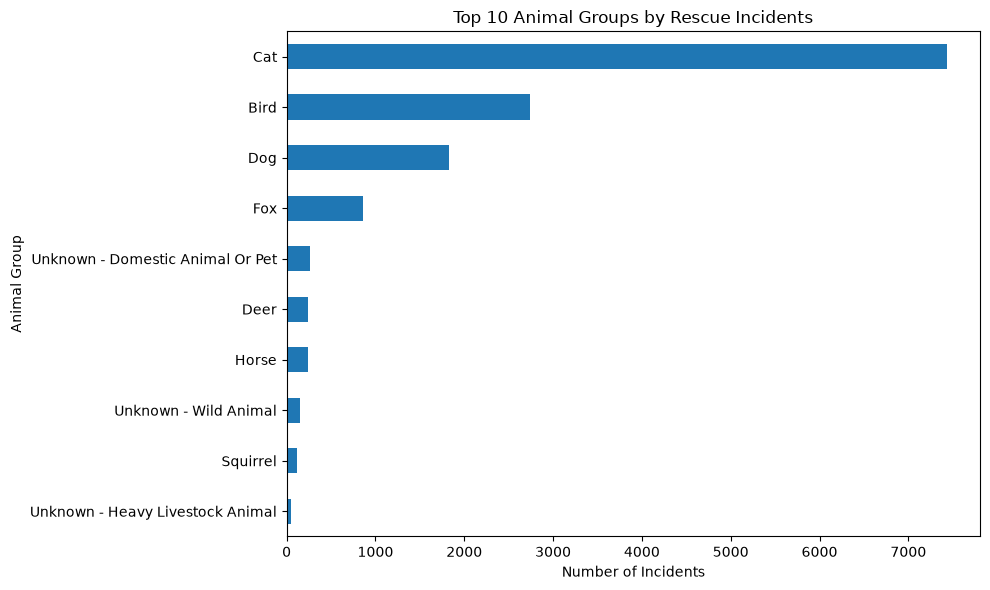

In [243]:
# Visualise the 10 most frequently recorded animal groups
top_animals = animal_counts.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_animals.plot(kind='barh')

plt.title('Top 10 Animal Groups by Rescue Incidents')
plt.xlabel('Number of Incidents')
plt.ylabel('Animal Group')
plt.tight_layout()
plt.show()


### Key Findings

- Cats accounted for **7,435 incidents (52.93%)**, making them the most frequently recorded animal group.
- Birds accounted for **2,743 incidents (19.53%)**, followed by dogs with **1,825 incidents (12.99%)**.
- Together, cats, birds and dogs represented approximately **85.45%** of all recorded incidents.
- These figures represent recorded incidents, not the number of individual animals rescued.


## EDA 2. How have animal rescue incidents changed over the years?

This analysis examines the annual number of recorded incidents to identify long-term changes in animal rescue activity.


In [244]:
yearly_incidents = df_clean.groupby('CalYear').size()

print(yearly_incidents)

CalYear
2009     568
2010     611
2011     620
2012     603
2013     585
2014     583
2015     540
2016     604
2017     539
2018     610
2019     604
2020     758
2021     885
2022    1029
2023    1193
2024    1326
2025    1414
2026     974
dtype: int64


In [245]:
print("Highest incident year:")
print(yearly_incidents.idxmax(), "-", yearly_incidents.max())

print("\nLowest incident year:")
print(yearly_incidents.idxmin(), "-", yearly_incidents.min())

Highest incident year:
2025 - 1414

Lowest incident year:
2017 - 539


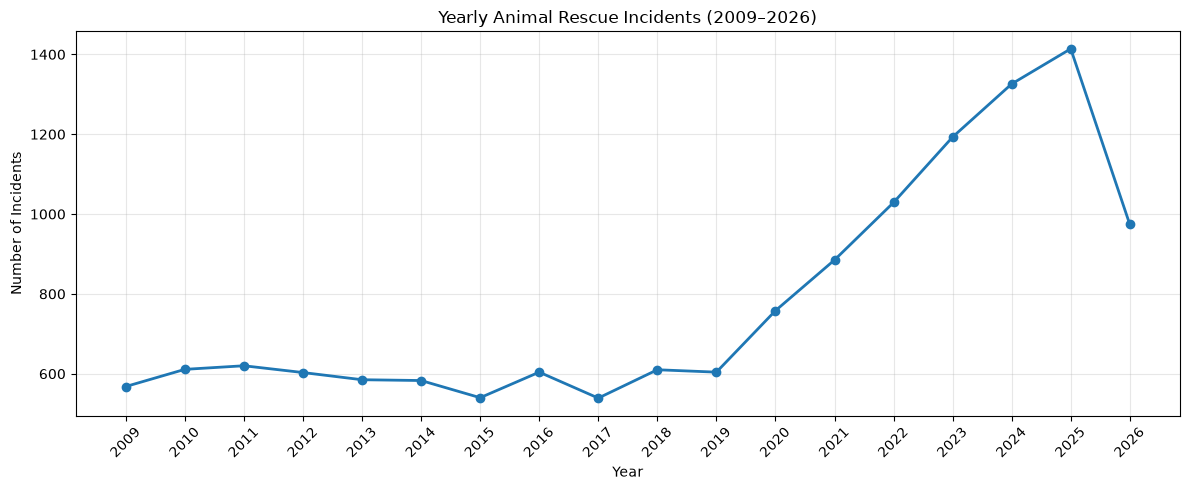

In [246]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_incidents.index,
    yearly_incidents.values,
    marker='o',
    linewidth=2
)

plt.title('Yearly Animal Rescue Incidents (2009–2026)')
plt.xlabel('Year')
plt.ylabel('Number of Incidents')
plt.xticks(yearly_incidents.index, rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Key Findings

- Annual incident counts were relatively stable from 2009 to 2019, ranging from **539 to 620 incidents**.
- Counts increased from 2020 onward, reaching **1,414 incidents in 2025**, the highest complete-year total in the dataset.
- The 2025 count was approximately **162.3% higher** than the 2017 count of 539.
- The 2026 total of 974 covers only January to July, so it should not be compared directly with full-year totals.


## EDA 3. Which months have the highest number of animal rescue incidents?

This analysis compares monthly incident totals using complete years (2009–2025). The incomplete 2026 data is excluded.


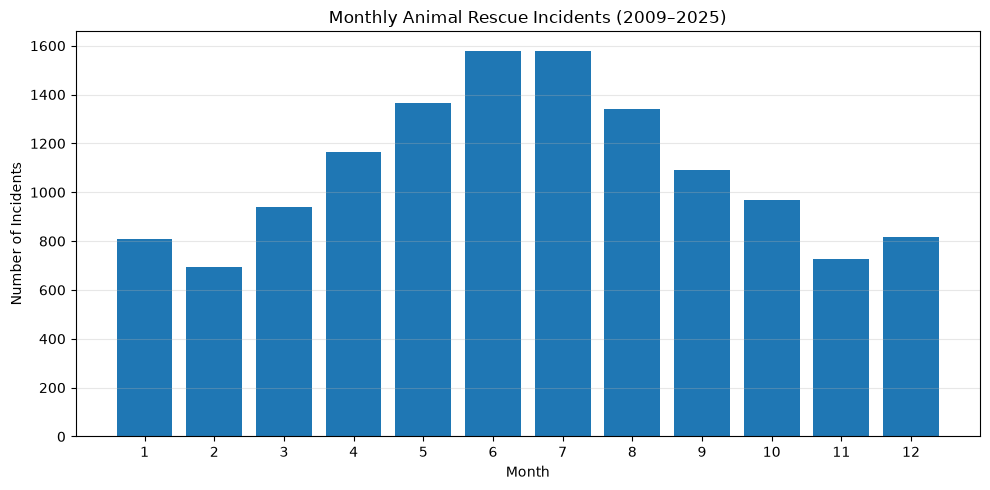

Month
1      810
2      692
3      938
4     1164
5     1366
6     1580
7     1580
8     1339
9     1092
10     970
11     725
12     816
dtype: int64

Highest incident month: 6
Lowest incident month: 2


In [247]:
# Exclude incomplete 2026 data
complete_years = df_clean[df_clean['CalYear'] < 2026]

# Count incidents for each month
monthly_incidents = complete_years.groupby('Month').size()

# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(monthly_incidents.index, monthly_incidents.values)

plt.title('Monthly Animal Rescue Incidents (2009–2025)')
plt.xlabel('Month')
plt.ylabel('Number of Incidents')
plt.xticks(range(1, 13))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(monthly_incidents)
print("\nHighest incident month:", monthly_incidents.idxmax())
print("Lowest incident month:", monthly_incidents.idxmin())

In [248]:
# Count the calendar days belonging to each month across 2009–2025
all_days = pd.date_range('2009-01-01', '2025-12-31', freq='D')
days_per_month = pd.Series(all_days.month).value_counts().sort_index()

# Calculate the average number of incidents per calendar day for each month
daily_average = (monthly_incidents / days_per_month).round(2)

print("Average incidents per day by month:")
print(daily_average)

print("\nHighest daily average month:", daily_average.idxmax())
print("Lowest daily average month:", daily_average.idxmin())


Average incidents per day by month:
Month
1     1.54
2     1.44
3     1.78
4     2.28
5     2.59
6     3.10
7     3.00
8     2.54
9     2.14
10    1.84
11    1.42
12    1.55
dtype: float64

Highest daily average month: 6
Lowest daily average month: 11


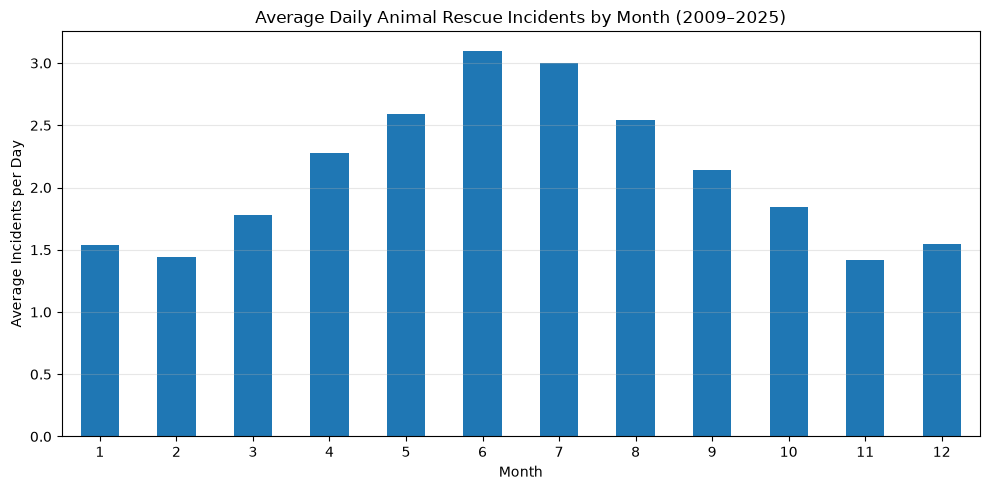

In [249]:
plt.figure(figsize=(10, 5))
daily_average.plot(kind='bar')

plt.title('Average Daily Animal Rescue Incidents by Month (2009–2025)')
plt.xlabel('Month')
plt.ylabel('Average Incidents per Day')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Key Findings

- June had the highest average daily incident count at **3.10 incidents per day**, followed by July at **3.00**.
- November had the lowest average at **1.42 incidents per day**.
- The daily averages account for the different number of days in each month and include leap years.
- The pattern indicates higher recorded activity during late spring and summer, although this analysis alone does not explain the reasons.


## EDA 4. At what time of day do animal rescue incidents occur most frequently?

This analysis examines the distribution of incidents across the 24 hours of the day.

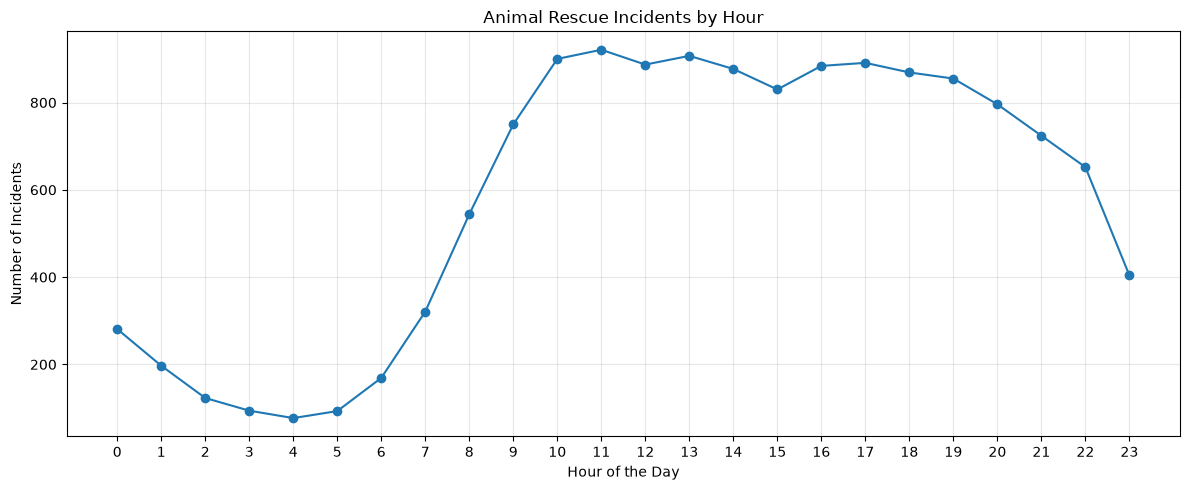

Hour
0     281
1     197
2     123
3      94
4      77
5      93
6     169
7     321
8     544
9     750
10    900
11    921
12    887
13    907
14    877
15    830
16    884
17    891
18    869
19    855
20    796
21    724
22    652
23    404
Name: count, dtype: int64

Busiest hour: 11
Quietest hour: 4


In [250]:
hourly_incidents = df_clean['Hour'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(hourly_incidents.index, hourly_incidents.values, marker='o')

plt.title('Animal Rescue Incidents by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Incidents')
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(hourly_incidents)
print("\nBusiest hour:", hourly_incidents.idxmax())
print("Quietest hour:", hourly_incidents.idxmin())

### Key Findings

- 11:00 AM recorded the highest number of incidents (921).
- 4:00 AM recorded the lowest number of incidents (77).
- Rescue activity increases during the morning and remains high throughout the afternoon.
- Incident frequency decreases during late-night and early-morning hours.

## EDA 5. What are the most common animal rescue operations?

This analysis identifies the most frequently recorded rescue operation types.

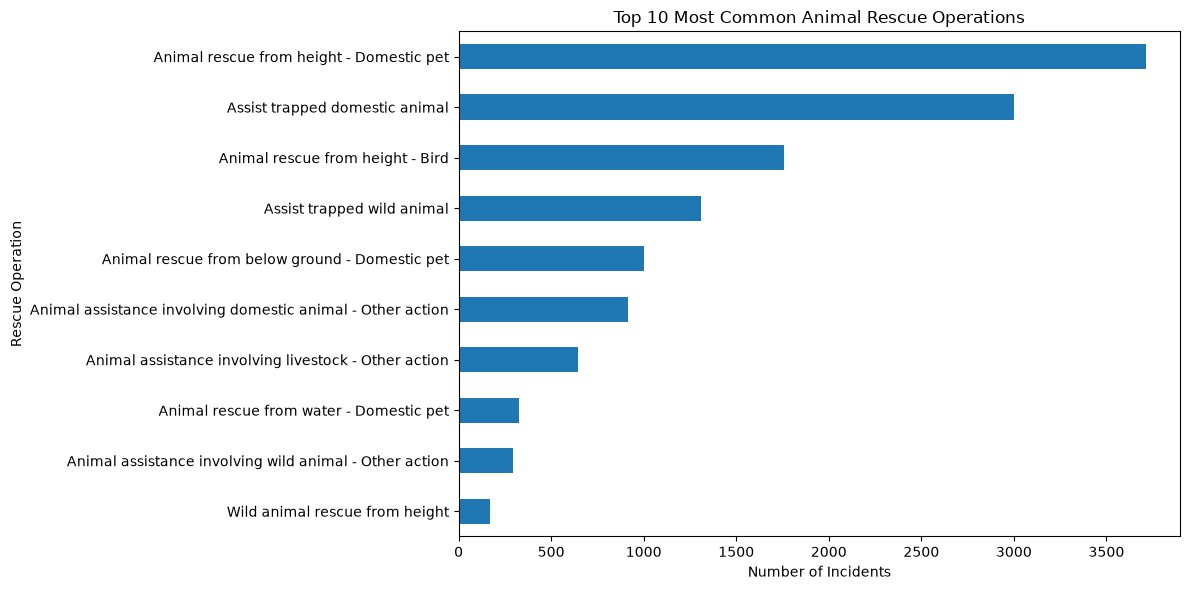

SpecialServiceType
Animal rescue from height - Domestic pet                      3712
Assist trapped domestic animal                                2999
Animal rescue from height - Bird                              1758
Assist trapped wild animal                                    1308
Animal rescue from below ground - Domestic pet                1002
Animal assistance involving domestic animal - Other action     917
Animal assistance involving livestock - Other action           643
Animal rescue from water - Domestic pet                        325
Animal assistance involving wild animal - Other action         292
Wild animal rescue from height                                 170
Name: count, dtype: int64


In [251]:
operation_counts = df_clean['SpecialServiceType'].value_counts()

plt.figure(figsize=(12, 6))
operation_counts.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Most Common Animal Rescue Operations')
plt.xlabel('Number of Incidents')
plt.ylabel('Rescue Operation')
plt.tight_layout()
plt.show()

print(operation_counts.head(10))

### Key Findings

- Animal rescue from height involving domestic pets was the most common operation (3,712 incidents).
- Assisting trapped domestic animals ranked second (2,999 incidents).
- Bird rescues from height ranked third (1,758 incidents).
- The results indicate that rescues involving domestic animals, particularly cats and other pets, represent a major part of the recorded operations.

## EDA 6. Which boroughs record the most animal rescue incidents?

This analysis compares recorded incident counts across boroughs. Counts are not adjusted for population or borough area.

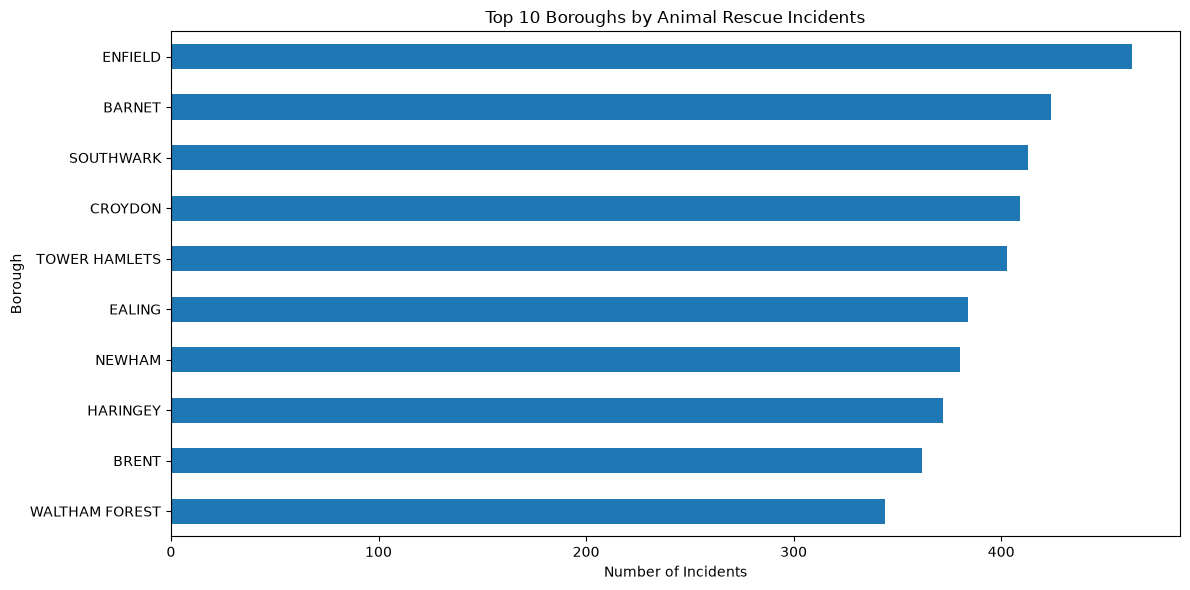

Borough
ENFIELD           463
BARNET            424
SOUTHWARK         413
CROYDON           409
TOWER HAMLETS     403
EALING            384
NEWHAM            380
HARINGEY          372
BRENT             362
WALTHAM FOREST    344
Name: count, dtype: int64


In [252]:
borough_counts = df_clean['Borough'].dropna().value_counts()

plt.figure(figsize=(12, 6))
borough_counts.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Boroughs by Animal Rescue Incidents')
plt.xlabel('Number of Incidents')
plt.ylabel('Borough')
plt.tight_layout()
plt.show()

print(borough_counts.head(10))

### Key Findings

- Enfield recorded the highest number of animal rescue incidents (463).
- Barnet ranked second (424), followed by Southwark (413).
- Croydon and Tower Hamlets also recorded relatively high incident counts.
- These results show the distribution of recorded incidents, not necessarily the risk of animal incidents per resident or per square kilometre.

## EDA 7. How do rescue operations differ across animal groups?

This analysis compares animal groups with their most frequently recorded rescue operation types.

In [253]:
# Create a cross-tabulation of animal groups and rescue operation types
animal_operations = pd.crosstab(
    df_clean['AnimalGroupParent'],
    df_clean['SpecialServiceType']
)

# Get the six most frequently recorded animal groups
top_animals = df_clean['AnimalGroupParent'].value_counts().head(6).index

# Find the three most common rescue operations for each animal group
results = []

for animal in top_animals:
    top_operations_for_animal = animal_operations.loc[animal].nlargest(3)

    for operation, count in top_operations_for_animal.items():
        results.append({
            'Animal': animal,
            'Rescue Operation': operation,
            'Incidents': count
        })

animal_operation_summary = pd.DataFrame(results)
print(animal_operation_summary.to_string(index=False))


                          Animal                                           Rescue Operation  Incidents
                             Cat                   Animal rescue from height - Domestic pet       3400
                             Cat                             Assist trapped domestic animal       2138
                             Cat             Animal rescue from below ground - Domestic pet        722
                            Bird                           Animal rescue from height - Bird       1744
                            Bird                                 Assist trapped wild animal        494
                            Bird     Animal assistance involving wild animal - Other action        128
                             Dog                             Assist trapped domestic animal        685
                             Dog             Animal rescue from below ground - Domestic pet        247
                             Dog                    Animal rescue from wa

### Key Findings

- Cats and birds were most frequently involved in rescue operations from heights.
- Dogs were most commonly involved in incidents requiring assistance for trapped domestic animals.
- Foxes were most frequently recorded in operations involving trapped wild animals.
- Horse incidents most commonly involved animal rescue from water.
- The results indicate differences in rescue operation patterns across animal groups.

## EDA 8. Which rescue operations account for the most total pump-hours?

This analysis sums recorded pump-hours by rescue operation. Missing pump-hour values are excluded automatically by the sum.

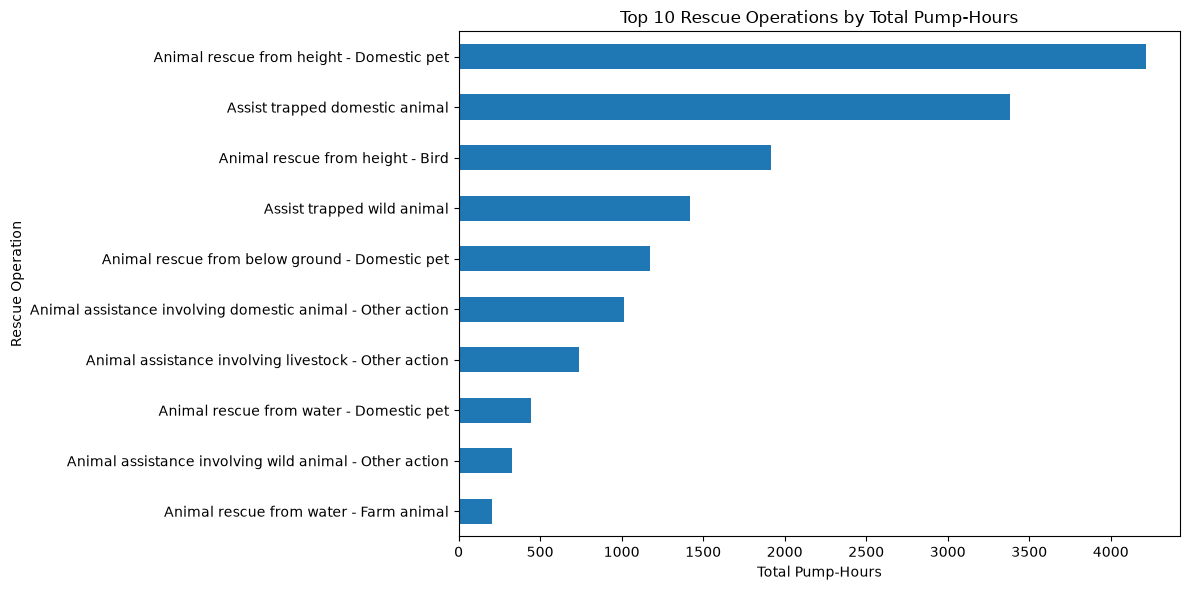

SpecialServiceType
Animal rescue from height - Domestic pet                      4214.0
Assist trapped domestic animal                                3385.0
Animal rescue from height - Bird                              1918.0
Assist trapped wild animal                                    1419.0
Animal rescue from below ground - Domestic pet                1173.0
Animal assistance involving domestic animal - Other action    1012.0
Animal assistance involving livestock - Other action           737.0
Animal rescue from water - Domestic pet                        444.0
Animal assistance involving wild animal - Other action         326.0
Animal rescue from water - Farm animal                         205.0
Name: PumpHoursTotal, dtype: float64


In [254]:
resource_usage = (
    df_clean.groupby('SpecialServiceType')['PumpHoursTotal']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
resource_usage.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Rescue Operations by Total Pump-Hours')
plt.xlabel('Total Pump-Hours')
plt.ylabel('Rescue Operation')
plt.tight_layout()
plt.show()

print(resource_usage.head(10))

### Key Findings

- Animal rescue from height involving domestic pets consumed the highest total pump-hours (4,214).
- Assisting trapped domestic animals ranked second (3,385 pump-hours).
- Bird rescues from height ranked third (1,918 pump-hours).
- Operations involving domestic animals account for a substantial share of the recorded resource usage.
- Missing pump-hour values were excluded from the calculation.

## EDA 9. Is pump count associated with incident cost?

This analysis examines the relationship between the number of pumps recorded and the incident's notional cost. Correlation measures association, not causation.

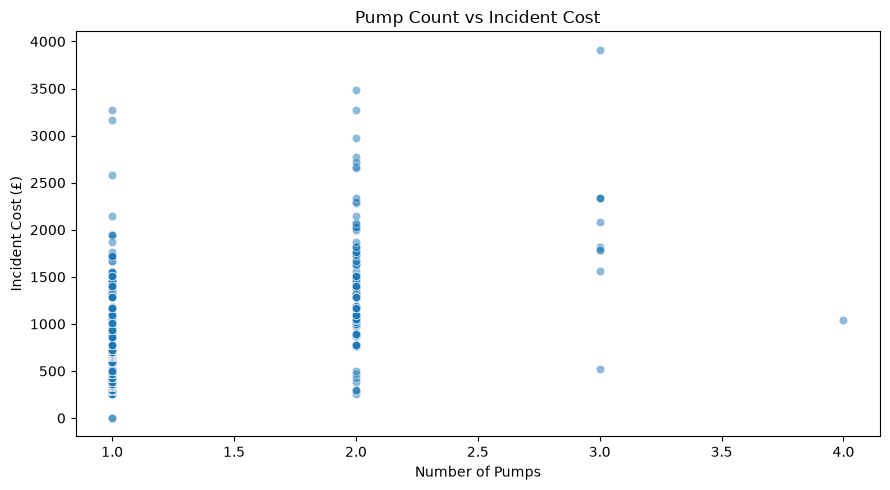

                         PumpCount  IncidentNotionalCost(£)
PumpCount                 1.000000                 0.488188
IncidentNotionalCost(£)   0.488188                 1.000000


In [255]:
cost_data = df_clean.dropna(
    subset=['PumpCount', 'IncidentNotionalCost(£)']
)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=cost_data,
    x='PumpCount',
    y='IncidentNotionalCost(£)',
    alpha=0.5
)

plt.title('Pump Count vs Incident Cost')
plt.xlabel('Number of Pumps')
plt.ylabel('Incident Cost (£)')
plt.tight_layout()
plt.show()

print(cost_data[['PumpCount', 'IncidentNotionalCost(£)']].corr())

### Key Findings

- Pump count and incident cost show a moderate positive correlation (0.488).
- Incidents involving more pumps tend to have higher recorded costs.
- The relationship is not perfect, suggesting that other factors may influence incident costs.
- Correlation does not establish causation.

## EDA 10. How are pump-hours distributed across common rescue operations?

This analysis compares the distribution of recorded pump-hours for the eight most frequent rescue operation types.

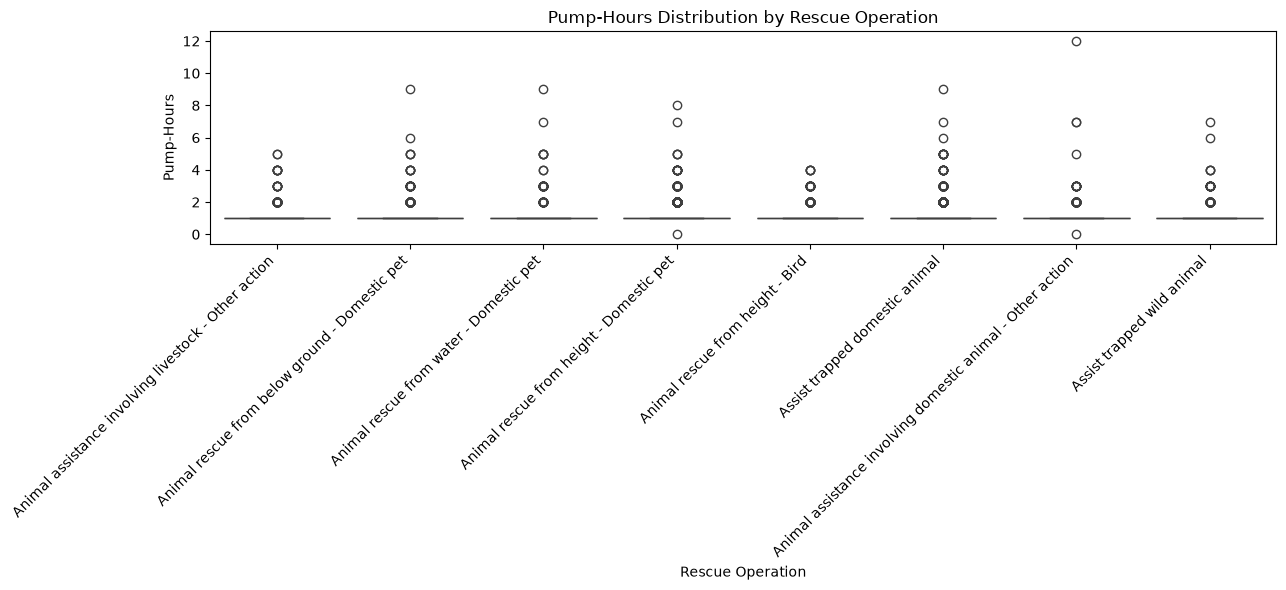

In [256]:
duration_data = df_clean.dropna(subset=['PumpHoursTotal'])

top_operations = (
    duration_data['SpecialServiceType']
    .value_counts()
    .head(8)
    .index
)

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=duration_data[
        duration_data['SpecialServiceType'].isin(top_operations)
    ],
    x='SpecialServiceType',
    y='PumpHoursTotal'
)

plt.title('Pump-Hours Distribution by Rescue Operation')
plt.xlabel('Rescue Operation')
plt.ylabel('Pump-Hours')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [257]:
# Summarise pump-hour distribution for the eight most common operation types
duration_summary = (
    duration_data[duration_data['SpecialServiceType'].isin(top_operations)]
    .groupby('SpecialServiceType')['PumpHoursTotal']
    .agg(Incidents='count', Median='median', Average='mean', Maximum='max')
    .sort_values('Median', ascending=False)
)

print(duration_summary.round(2))


                                                    Incidents  Median  \
SpecialServiceType                                                      
Animal assistance involving domestic animal - O...        904     1.0   
Animal assistance involving livestock - Other a...        639     1.0   
Animal rescue from below ground - Domestic pet            992     1.0   
Animal rescue from height - Bird                         1753     1.0   
Animal rescue from height - Domestic pet                 3693     1.0   
Animal rescue from water - Domestic pet                   318     1.0   
Assist trapped domestic animal                           2980     1.0   
Assist trapped wild animal                               1299     1.0   

                                                    Average  Maximum  
SpecialServiceType                                                    
Animal assistance involving domestic animal - O...     1.12     12.0  
Animal assistance involving livestock - Other a...     1

### Key Findings

- The median recorded pump-hours was **1.0 hour for each of the eight most common operation types**.
- The highest maximum in these eight groups was **12 pump-hours**, recorded for "Animal assistance involving domestic animal - Other action".
- Maximum values differed across operation types; the boxplot and summary table show both typical values and unusually long incidents.
- Pump-hour values are missing for some records, so the summary uses incidents with a recorded pump-hour value only.


# Executive Summary and Conclusion

## Main Findings

- **Animal groups:** Cats were the most frequently recorded group (52.93%), followed by birds (19.53%) and dogs (12.99%). These three groups accounted for approximately 85.45% of recorded incidents.
- **Yearly trend:** Annual counts were relatively stable from 2009 to 2019, then increased from 2020 onward. The highest complete-year count was 1,414 in 2025.
- **Seasonal pattern:** June had the highest average daily incident count (3.10), while November had the lowest (1.42).
- **Daily pattern:** 11:00 was the busiest hour (921 incidents), while 04:00 was the quietest (77 incidents).
- **Rescue operations:** Rescues from height involving domestic pets were the most frequently recorded operation (3,712 incidents).
- **Geographical distribution:** Enfield had the highest recorded borough count (463), followed by Barnet (424) and Southwark (413). These are raw counts, not population-adjusted rates.
- **Resource usage:** Rescues from height involving domestic pets accounted for the highest total recorded pump-hours (4,214).
- **Cost relationship:** Pump count and incident notional cost had a moderate positive correlation of approximately 0.488. This indicates an association, not proof that additional pumps cause higher costs.
- **Pump-hour distribution:** For the eight most common operation types, the median recorded pump-hours was one hour. Some incidents had substantially higher values, reaching 12 hours.

## Data Limitations

- The 2026 data covers January to July only and is incomplete.
- PumpCount, PumpHoursTotal and IncidentNotionalCost contain missing values. These were not replaced with zero; analyses using these fields exclude missing values.
- Latitude and longitude are missing for many incidents. Six records with zero coordinates were treated as missing, while other unusual coordinate values were retained for further verification.
- Borough comparisons use raw incident counts and do not account for population, area or animal population.
- The dataset records incidents, not unique animals; one animal may not necessarily correspond to one incident.

## Conclusion

The analysis identifies clear differences in the types, timing, locations and resource usage of recorded animal rescue incidents. Cats account for the largest share of incidents, rescue activity is higher during certain months and daytime hours, and domestic-pet rescues from height are the most frequently recorded operation. These findings describe patterns in the available records and can guide further investigation, but they do not by themselves establish the causes of those patterns or determine staffing requirements.
